# Isolation Forest model for anomaly detection

## Imports

In [144]:
import pandas as pd
import numpy as np
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt

## Training the model

In [145]:
# Load data 
data = pd.read_parquet("../data/processed/turbine_cleaned.parquet")
data.sort_values(by="timestamp")
data

,timestamp,gearbox_oil_temp,gearbox_bearing_temp,vibration_x,vibration_y,vibration_z,oil_pressure,particle_count
0,2025-01-01 00:00:00,59.24,65.85,0.0109,0.0092,0.0130,4.53,100
1,2025-01-01 00:10:00,60.12,66.83,0.0076,0.0065,0.0092,4.48,100
2,2025-01-01 00:20:00,59.50,65.16,0.0160,0.0136,0.0193,4.53,100
3,2025-01-01 00:30:00,60.28,65.80,0.0164,0.0140,0.0197,4.54,100
4,2025-01-01 00:40:00,60.72,66.84,0.0177,0.0151,0.0213,4.49,100
...,...,...,...,...,...,...,...,...
262795,2029-12-30 23:10:00,61.80,87.31,0.0243,0.0206,0.0291,4.19,1413
262796,2029-12-30 23:20:00,61.52,89.94,0.0287,0.0244,0.0345,4.23,1413
262797,2029-12-30 23:30:00,60.97,86.79,0.0247,0.0210,0.0296,4.17,1413
262798,2029-12-30 23:40:00,62.49,89.88,0.0184,0.0156,0.0221,4.22,1413


Drop timestamp column

In [146]:
X = data.drop(columns=["timestamp"])
X

,gearbox_oil_temp,gearbox_bearing_temp,vibration_x,vibration_y,vibration_z,oil_pressure,particle_count
0,59.24,65.85,0.0109,0.0092,0.0130,4.53,100
1,60.12,66.83,0.0076,0.0065,0.0092,4.48,100
2,59.50,65.16,0.0160,0.0136,0.0193,4.53,100
3,60.28,65.80,0.0164,0.0140,0.0197,4.54,100
4,60.72,66.84,0.0177,0.0151,0.0213,4.49,100
...,...,...,...,...,...,...,...
262795,61.80,87.31,0.0243,0.0206,0.0291,4.19,1413
262796,61.52,89.94,0.0287,0.0244,0.0345,4.23,1413
262797,60.97,86.79,0.0247,0.0210,0.0296,4.17,1413
262798,62.49,89.88,0.0184,0.0156,0.0221,4.22,1413


In [147]:
model = IsolationForest(contamination=0.05, random_state=42)
model.fit(X)

,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.05
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


## Predictions

In [148]:
predictions = model.predict(data.drop(columns=["timestamp"]))
anomaly_scores = model.decision_function(data.drop(columns=["timestamp"]))

results = pd.DataFrame({
    "timestamp":data.loc[data.index, "timestamp"],
    "anomaly" : predictions == -1,
    "anomaly_score": anomaly_scores
})

results["anomaly"].mean()

np.float64(0.05)

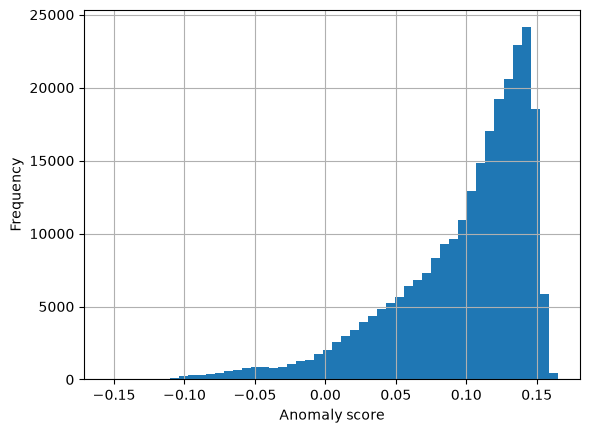

In [149]:
results["anomaly_score"].hist(bins=50)
plt.xlabel("Anomaly score")
plt.ylabel("Frequency")
plt.show()

## Plotting

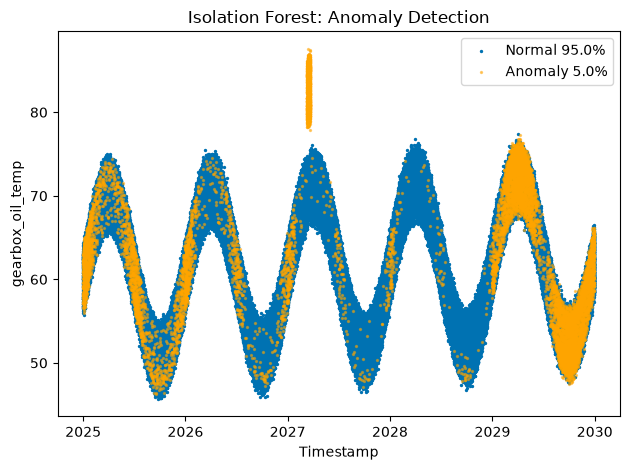

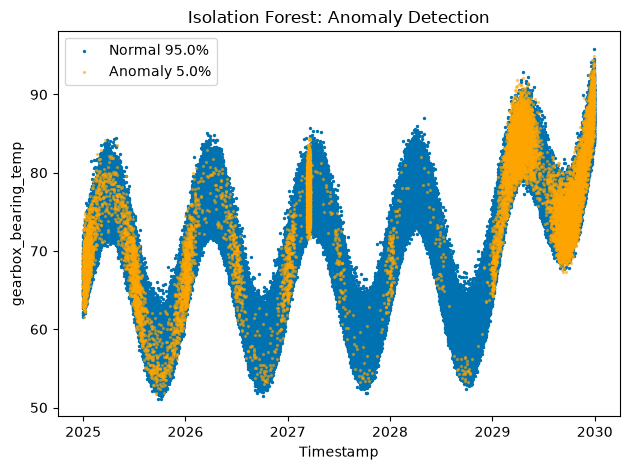

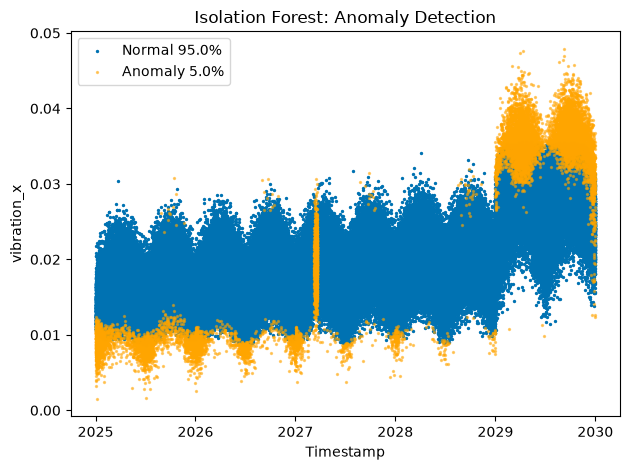

In [ ]:
labels = X.columns

# Anomalies
anomalies = results["anomaly"]
# Normaal measurements
normal = ~results["anomaly"]


for colname in labels:
    
    plt.scatter(
        data.loc[normal, "timestamp"],
        data.loc[normal, colname],
        s=2,
        color="#0072B2",
        label=f"Normal {round(normal.sum() / (normal.sum() + anomalies.sum()), 2) * 100}%"
    )
    
    plt.scatter(
        data.loc[anomalies, "timestamp"],
        data.loc[anomalies, colname],
        s=2,
        alpha=0.5,
        color="orange",
        label=f"Anomaly {round(anomalies.sum() / (normal.sum() + anomalies.sum()), 2) * 100}%"
    )

    plt.xlabel("Timestamp")
    plt.ylabel(f"{colname}")
    plt.title("Isolation Forest: Anomaly Detection")
    plt.legend()
    plt.tight_layout()
    plt.show()

## Maintenance alert 

6 consecutive measurements are considered as anomaly_window (anomaly detected for 6 measurements = 1 hour).

Anomaly window could last many hours so we send only one maintenance alert for each starting anomaly_window

In [151]:
n = 6

results["anomaly_window"] = (
    results["anomaly"]
    .rolling(window=n, min_periods=n)
    .sum()
    .eq(n)
)


results["previous_window"] = results["anomaly_window"].shift(1, fill_value=False)

# If anomaly window is True and previous window is false -> send maintenance alert
results["maintenance_alert"] = results["anomaly_window"] & ~results["previous_window"]

alert_mean = results["maintenance_alert"].mean()
alert_count = results["maintenance_alert"].sum()
alert_mean, alert_count

(np.float64(7.610350076103501e-05), np.int64(20))

In [152]:
duration_days = (results["timestamp"].max() - results["timestamp"].min()).total_seconds() / 86400 #seconds in a day
duration_months = duration_days / 30.437 #avg days in a month

# maintenance alerts per month
MaintenancePerMonth = alert_count / duration_months
MaintenancePerMonth

np.float64(0.33355743362798185)